# 5장 1강: 배깅과 랜덤포레스트

## 실습 목표
이번 실습에서는 **Ames Housing** 데이터를 이용하여 배깅과 랜덤포레스트의 핵심 원리를 확인합니다.

- 하나의 의사결정나무와 여러 나무를 모은 배깅의 차이를 확인합니다.
- 배깅에서 여러 회귀 모델의 예측을 평균내는 이유를 이해합니다.
- 랜덤포레스트의 부트스트랩과 피처 무작위 선택 개념을 확인합니다.
- OOB Score와 Feature Importance를 확인합니다.
- 여러 나무를 평균낼 때 분산이 줄어드는 이유를 설명합니다.

> 교안에 나온 범위만 사용합니다.

## 실습 환경 / 데이터
- Python, pandas, numpy, matplotlib, scikit-learn
- 데이터: `Ames_Housing.csv`
- 예측 대상: `SalePrice`

사용 특성:
`OverallQual`, `GrLivArea`, `GarageCars`, `GarageArea`, `TotalBsmtSF`, `1stFlrSF`,
`2ndFlrSF`, `FullBath`, `TotRmsAbvGrd`, `YearBuilt`, `YearRemodAdd`, `Fireplaces`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.metrics import r2_score

house = pd.read_csv("C:/Users/jihun/OneDrive/Desktop/DS 실습자료/LV2/실전 머신러닝/데이터/Ames_Housing.csv")

features = [
    "OverallQual","GrLivArea","GarageCars","GarageArea",
    "TotalBsmtSF","1stFlrSF","2ndFlrSF","FullBath",
    "TotRmsAbvGrd","YearBuilt","YearRemodAdd","Fireplaces"]

X = house[features]
y = house["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 필수 1. 하나의 나무와 Bagging 비교

## 문제 1. Decision Tree 하나를 학습하세요.
1. `DecisionTreeRegressor(random_state=42)` 사용
2. Train 학습
3. Train/Test 예측
4. Train R², Test R² 계산
5. 두 점수 차이 해석

In [2]:
# TODO
tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train, y_train)

tree_train_pred = tree.predict(X_train)
tree_test_pred = tree.predict(X_test)

tree_train_r2 = r2_score(y_train, tree_train_pred)
tree_test_r2 = r2_score(y_test, tree_test_pred)

print("Train R²:", tree_train_r2)
print("Test R²:", tree_test_r2)

Train R²: 0.9999007920351307
Test R²: 0.7938734688847873


### tree = DecisionTreeRegressor(random_state=42) : 깊이를 제한하지 않은 회귀나무
### -> max_depth를 지정하지 않았기 때문에 무한하게 학습을 할 수도 있겠다라고 판단할 수 있지만
### 더 나눌 수 없거나 기본 분할 조건을 만족하지 못하면 멈춘다.

### Train이 1에 가깝다는 것의 의미
### -> 일반적으로 R²이 1에 가깝다는 것은 모델이 충분히 해당 데이터에 대한 설명력을 가지고 있다는 것이지만
### 지나치게 성능이 높은 경우 과적합 위험을 의심하여 추가적인 검증이 필요하다. 

### Q1. Train R²는 매우 높은데 Test R²가 더 낮다면 무엇을 의미하나요?
### -> 이는 하나의 나무가 학습 데이터 변화에 민감한 분산이 큰 모델임을 보여준다.
### Decision Tree의 한 그루는 불안정할 수 있다.


## 문제 2. Bagging을 적용하세요.
1. 기본 모델은 `DecisionTreeRegressor(random_state=42)`
2. `BaggingRegressor`
3. `n_estimators=50`
4. `random_state=42`
5. Test R² 계산
6. `max_features="sqrt`
7. Decision Tree 하나와 비교

In [3]:
# TODO
bagging = BaggingRegressor(
    estimator=DecisionTreeRegressor(random_state=42),
    n_estimators=50,
    random_state=42)

bagging.fit(X_train, y_train)
bagging_test_pred = bagging.predict(X_test)
bagging_test_r2 = r2_score(y_test, bagging_test_pred)

display(pd.DataFrame({
    "model": ["Decision Tree", "Bagging"],
    "test_r2": [tree_test_r2, bagging_test_r2]}))

,model,test_r2
0,Decision Tree,0.793873
1,Bagging,0.889347


### 배깅, 나무 50개를 평균한다는 것의 의미
### 어떤 트리가 특정 주택을 높게 예측하고 다른 트리가 낮게 예측하면 평균에서 오류가 일부 상쇄될 수 있다.
### 다만, 여러 트리가 모두 같은 방향으로 크게 틀리는 경우 평균을 해도 오류가 남는다.
### 따라서 무조건 모델 수만 늘리면 오류를 해결할 수 있는 것은 아니다.

### Q2. 왜 각 나무를 서로 다른 부트스트랩 샘플로 학습하나요?

### 완전히 같은 데이터로 여러 나무를 구성하게 되면 모델이 비슷한 학습을 보이기 때문에
### 앙상블 효과가 적어짐
### 부트스트랩으로 학습 데이터셋을 조금씩 바꾸면 나무마다 다른 오류 패턴을 학습하고
### 평균을 내는 과정에서 오류가 일부 상쇄될 가능성이 있음

# 필수 2. Random Forest의 OOB Score와 Feature Importance

## 문제 1. OOB Score를 확인하세요.
1. `RandomForestRegressor`
2. `n_estimators=100`
3. `bootstrap=True`
4. `oob_score=True`
5. `random_state=42`
6. Test R²와 `oob_score_` 출력

In [4]:
# TODO
rf = RandomForestRegressor(
    n_estimators=100,
    bootstrap=True,
    max_features="sqrt",
    oob_score=True,
    random_state=42,
    n_jobs=-1)

rf.fit(X_train, y_train)
rf_test_pred = rf.predict(X_test)

print("Test R²:", r2_score(y_test, rf_test_pred))
print("OOB Score:", rf.oob_score_)

Test R²: 0.8922042387004825
OOB Score: 0.833431951772095


### 각 Train 표본의 OOB 예측을 따로 모은다.
### -> 어떤 Train 주택 A를 예측할 때 A를 한번도 뽑지 않은 나무들만 사용한다.
### 1, 4, 7번 나무가 A를 학습하지 않았다면 A의 예측 평균을 사용한다.

### Test R²은 0.89 <- 별도 100개의 나무 전체의 평균 
### OOB Score <- 각 Train 표본을 학습하지 않은 나무들의 표본 예측 결과
### OOB 계산식
### $$P(\mathrm{OOB})=\left(1-\frac1N\right)^N\approx e^{-1}\approx0.368$$

### OOB가 0.83이라는 것의 의미
### -> OOB 예측의 제곱오차 합이 Train 실제 평균 가격을 예측하는 기준보다 83%정도 작다.
### OOB 지표도 음수가 될 수 있다.

### 별도 검증이나 교차검증을 대체할 수 있는가?
### OOB는 부트스트랩 학습의 남은 데이터셋을 이용하니까 Train / Validation 분할없이 모델을 점검하는 데 편리
### 목적에 맞는 데이터 셋과 설계에 따라 검증이나 교차검증이 추가적으로필요한 경우들이 있다.
### 독립적인 결과로 해석하는 경우는 적다.

### Q3. OOB 샘플은 무엇인가요?
### OOB 샘플은 부트스트랩 샘플링에서 한 번도 선택되지 않은 데이터

### Q4. OOB Score가 교차검증을 완전히 대체하나요?
### 완전히 대체하지는 않는다. OOB는 편리한 추정치를 산출하지만 
### 데이터가 적은 상황, 신뢰도가 더 높게 필요한 상황이라면 교차검증과 함께 쓰는 것이 일반적이다.

## 문제 2. Feature Importance를 확인하세요.
1. `feature_importances_` 사용
2. 특성명과 중요도 DataFrame 생성
3. 내림차순 정렬
4. 막대그래프
5. 가장 높은 중요도 특성 확인

,feature,importance
0,OverallQual,0.230327
1,GrLivArea,0.172155
2,GarageCars,0.113031
9,YearBuilt,0.094882
4,TotalBsmtSF,0.085023
5,1stFlrSF,0.080528
3,GarageArea,0.059085
6,2ndFlrSF,0.047577
10,YearRemodAdd,0.039302
11,Fireplaces,0.028686


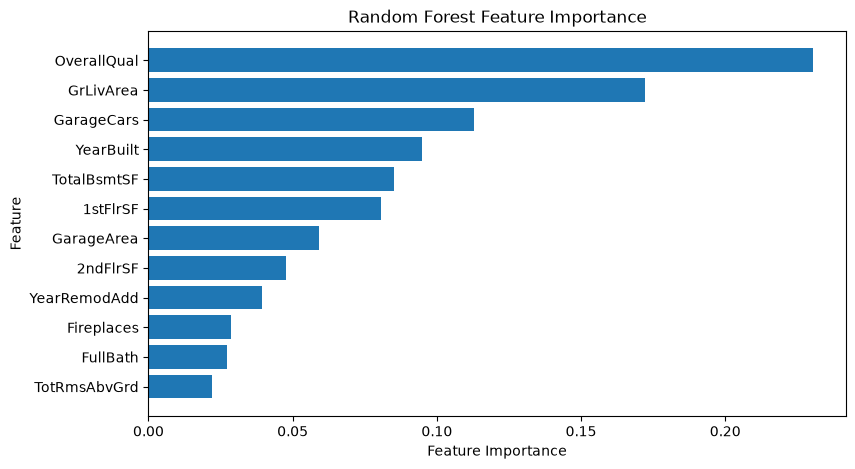

In [5]:
# TODO
importance_df = pd.DataFrame({
    "feature": features,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(importance_df["feature"], importance_df["importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.show()

### OverallQual의 막대가 0.23까지 나타나있고, GrLivArea가 0.17이라는 것은
### 품질과 지상 면적에 약 40%정도의 설명력을 가지고 있다는 것으로 해석할 수 있음
### 이 두 가지 지표로 전체 중요도의 40%정도 이기때문에 가격변동(Y)의 40%는 중요한 참고 데이터로 사용함
### 단 R²이 40%정도다라고 설명하는 것은 적절하지 않음

### 중요도 0.23을 어떻게 해석할 수 있는 지?
### 가장 정확한 정의는 랜덤포레스트의 불순도 기반 중요도에서 OverallQual(품질)이 약 23%정도 차지했다.

### 잘못된 해석
### 품질이 집값의 23%를 결정한다.
### 품질 1등급을 올리면 가격이 23%상승한다.

### 낮은 중요도는 쓸모없는 변수라는 것을 의미하는가?
### -> 아님, 해당 모델이 예측할 때 조금 덜 힌트를 얻었다는 식으로 설명할 수 있음

### 중요도 해석 한계점
### 불순도 기반 중요도가 가능한 분할 지점이 많은 특성에 유리하게 작용
### 따라서 상관된 특성끼리 중요도가 나뉘거나 쏠리는 현상이 있을 수 있음

### 현재 이 모델에서 중요도는 품질 등급과 지상 면적이 가장 크다.
### 이 부분은 이 입력구성과 학습 설정에서 모델이 예측을 위해 사용한 분할 정보의 상대적 기여를 의미한다.

### Q5. Feature Importance가 높다는 것이 그 변수가 주택가격의 원인이라는 뜻인가요?
### 아니고, 중요도가 높다라는 것의 올바른 해석은 현재 모델이(설정 상태) 예측을 할 때 많이 활용했다는 의미

# 과제 1. 나무 수와 예측 안정성 확인

`tree_counts = [1, 10, 50, 100]`을 사용하세요.

각 나무 수에서:
1. RandomForestRegressor 생성
2. `bootstrap=True`, `random_state=42`
3. Train 학습
4. Test R² 계산
5. DataFrame 정리
6. 나무 수에 따른 성능 변화 확인
7. 여러 예측의 평균과 분산 감소 관계 설명

In [ ]:
# TODO

### Q6. 나무 수를 늘리면 왜 예측이 더 안정적으로 변하나요?

**답변:** 여기에 작성하세요.

### Q7. 나무 수를 계속 늘리면 분산이 무한히 0으로 줄어드나요?

**답변:** 여기에 작성하세요.

# 실습 마무리
1. 부트스트랩 샘플링은 어떤 방식인가요?
-> 원본 데이터셋에서 중복을 허용하여 같은 크기의 샘플을 추출

2. Bagging 회귀에서는 여러 모델의 예측을 어떻게 합치나요?
-> 여러 모델의 예측값의 평균

3. Random Forest가 Bagging에 추가하는 무작위성은 무엇인가요?
-> 각 트리 분할에서 일부 피처만 무작위 후보로 사용

4. OOB 샘플은 평균적으로 약 몇 %인가요?
-> 37% 

5. Feature Importance가 높다는 것은 무엇을 의미하나요?
-> 모델이 예측에 얼마나 많이 활용했는 지

6. Bagging이 Decision Tree와 특히 잘 맞는 이유는 무엇인가요?
-> Decision Tree는 기본적으로 분산이 큰 모델인데 배깅의 분산 감소 효과와 잘 맞음
